# Decision Tree Regression: 

**Goal:** Predict log price with a single regression tree, and find out which features the tree relies on.

**Setup:** Same cleaned data, same 80/20 split (`random_state=42`), and same 5-fold CV as the KNN notebook. Trees don't need scaling, so the categorical columns are one-hot encoded and the numeric columns pass through unchanged.

Sections:
1. Tune the tree with cross-validation on the training set only
2. Evaluate once on the test set
3. Feature importances
4. Error by price segment and luxury brand

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load the cleaned data saved from the KNN notebook's cleaning steps
df = pd.read_csv('../data/cardekho_clean.csv')
df['log_price'] = np.log(df['selling_price'])

num_cols = ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
cat_cols = ['brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']
X = df[num_cols + cat_cols]
y = df['log_price']

# Same split and CV as the KNN notebook so results are comparable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

LUXURY = ['Land Rover', 'Jaguar', 'Mercedes-Benz', 'Audi', 'BMW']

def evaluate(pred_log, name):
    rmse = np.sqrt(mean_squared_error(y_test, pred_log))
    r2 = r2_score(y_test, pred_log)
    mae = mean_absolute_error(np.exp(y_test), np.exp(pred_log))
    print(f"{name}: test RMSE (log) {rmse:.4f} | R2 {r2:.4f} | MAE Rs {mae:,.0f}")
    return {'model': name, 'test_rmse_log': round(rmse, 4), 'test_r2': round(r2, 4), 'test_mae_rs': round(mae)}

def segment_report(pred_log):
    d = pd.DataFrame({
        'actual': np.exp(y_test.values),
        'pred': np.exp(pred_log),
        'brand': X_test['brand'].values,
    })
    d['pct_error'] = np.abs(d['pred'] - d['actual']) / d['actual']
    d['segment'] = pd.qcut(d['actual'], 4, labels=['Q1 cheapest', 'Q2', 'Q3', 'Q4 priciest'])
    return d

def print_segments(pred_log):
    d = segment_report(pred_log)
    print(d.groupby('segment', observed=True)['pct_error'].mean().round(3))
    print(d[d['brand'].isin(LUXURY)].groupby('brand')['pct_error'].agg(['size', 'mean']).round(3))

def original_feature(name):
    # Maps one-hot names like 'cat__brand_Maruti' back to 'brand'
    name = name.split('__', 1)[1]
    for col in cat_cols + num_cols:
        if name == col or name.startswith(col + '_'):
            return col
    return name

print(X_train.shape, X_test.shape)

(12184, 11) (3046, 11)


## 1. Tune the tree

- `max_depth` limits how many questions the tree can ask in a row.
- `min_samples_leaf` limits how few cars a final prediction can be based on. Larger values smooth the predictions.

`max_features` controls how many features each split may consider. It made no difference in our first run, so we keep the grid small.

In [2]:
from sklearn.tree import DecisionTreeRegressor

preprocessor = ColumnTransformer(
    [('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
    remainder='passthrough'
)
tree_pipe = Pipeline([
    ('prep', preprocessor),
    ('tree', DecisionTreeRegressor(random_state=42))
])

param_grid = {
    'tree__max_depth': [None, 10, 15, 20],
    'tree__min_samples_leaf': [1, 5, 10, 20],
    'tree__max_features': [None, 0.5, 0.3],
}
grid_tree = GridSearchCV(tree_pipe, param_grid, cv=cv,
                         scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_tree.fit(X_train, y_train)
print("best params:", grid_tree.best_params_)
print("best CV RMSE (log):", round(-grid_tree.best_score_, 4))

best params: {'tree__max_depth': None, 'tree__max_features': None, 'tree__min_samples_leaf': 10}
best CV RMSE (log): 0.1948


## 2. Evaluate on the test set

The test set is used once, here, after the settings were chosen.

In [3]:
best_tree = grid_tree.best_estimator_
pred_tree = best_tree.predict(X_test)
tree_result = evaluate(pred_tree, 'Decision tree')

Decision tree: test RMSE (log) 0.1908 | R2 0.9201 | MAE Rs 110,091


## 3. Feature importances

One-hot encoding splits each categorical feature into many columns, so the helper adds them back together under the original feature name.

max_power            0.691
vehicle_age          0.217
engine               0.034
model                0.017
brand                0.015
mileage              0.009
km_driven            0.008
transmission_type    0.004
seller_type          0.003
seats                0.002
fuel_type            0.001
dtype: float64


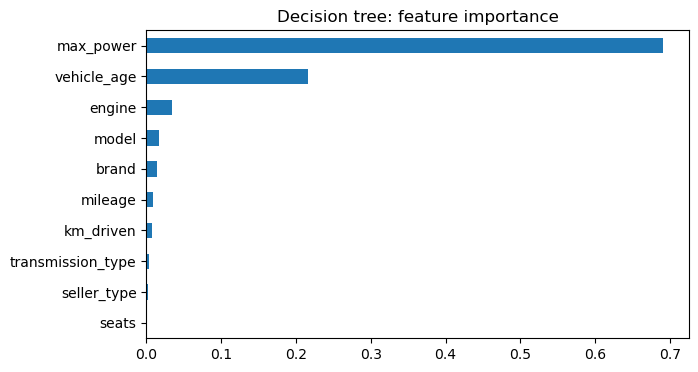

In [4]:
names = best_tree.named_steps['prep'].get_feature_names_out()
imp = pd.Series(best_tree.named_steps['tree'].feature_importances_, index=names)
grouped = imp.groupby([original_feature(n) for n in names]).sum().sort_values(ascending=False)
print(grouped.round(3))

grouped.head(10).sort_values().plot(kind='barh', figsize=(7, 4), title='Decision tree: feature importance')
plt.show()

Impurity-based importances favor features with many distinct values, so treat the exact percentages as approximate. The ranking is the useful part.

## 4. Error by price segment and luxury brand

The same breakdown is used in every model notebook, so the numbers can be compared directly.

In [5]:
print_segments(pred_tree)

segment
Q1 cheapest    0.186
Q2             0.131
Q3             0.113
Q4 priciest    0.148
Name: pct_error, dtype: float64
               size   mean
brand                     
Audi             33  0.205
BMW              78  0.182
Jaguar           14  0.332
Land Rover       11  0.268
Mercedes-Benz    58  0.205


## Results and takeaways

| Model | CV RMSE | Test RMSE | R² | MAE |
|---|---|---|---|---|
| Decision tree (depth None, min leaf 10) | 0.1948 | 0.1908 | 0.9201 | ₹110,091 |

- **The best settings are depth unlimited and min samples per leaf of 10.** The leaf limit is what controls overfitting here. The wider `max_features` search did not change the best setting.
- **Test error is close to CV error,** so the tuning did not overfit the test set.
- **`max_power` (0.69) and `vehicle_age` (0.22) account for most of the splits.** This matches the correlations in the EDA.
- **The tree is worse than KNN overall** and much worse on luxury brands, especially Jaguar (33% vs 18% for KNN). It is slightly better on the cheapest quarter (18.6% vs 19.8%).
- A single tree's predictions are step functions, so it cannot give smooth estimates for cars that fall between its leaves. This is one reason the random forest does better.